In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [3]:
df = pd.read_csv('2022mlbteams.csv')
df = df.drop([30, 31])
df = df.drop(columns=['#Bat', 'Tm', 'G'])
df

,BatAge,R/G,PA,AB,R,H,2B,3B,HR,RBI,...,OPS,OPS+,TB,GDP,HBP,SH,SF,IBB,LOB,PO
0,26.5,4.33,6027,5351,702,1232,262,24,173,658,...,0.689,95,2061,97,60,31,50,14,1039,0.0
1,27.5,4.87,6082,5509,789,1394,298,11,243,753,...,0.761,109,2443,103,66,1,36,13,1030,1.0
2,27.0,4.16,6049,5429,674,1281,275,25,171,639,...,0.695,99,2119,95,83,12,43,10,1095,0.0
3,28.8,4.54,6144,5539,735,1427,352,12,155,704,...,0.731,102,2268,131,63,12,50,23,1133,0.0
4,27.9,4.06,6072,5425,657,1293,265,31,159,620,...,0.698,94,2097,130,84,19,36,16,1100,0.0
5,29.3,4.23,6123,5611,686,1435,272,9,149,654,...,0.698,97,2172,127,73,16,35,9,1117,0.0
6,29.4,4.00,5978,5380,648,1264,235,18,156,618,...,0.676,85,2003,127,92,12,33,6,1020,0.0
7,25.9,4.31,6163,5558,698,1410,273,31,127,662,...,0.699,102,2126,119,81,22,52,36,1156,1.0
8,29.1,4.31,6105,5540,698,1408,280,34,149,669,...,0.713,91,2203,139,61,10,40,10,1113,0.0
9,27.9,3.44,5870,5378,557,1240,235,27,110,530,...,0.632,82,1859,108,58,10,44,8,1015,0.0


In [4]:
x = df.iloc[:, 0:26]
y = df.iloc[:, 26]
x.shape, y.shape

((30, 26), (30,))

In [5]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=21)

# max(sum((xi dot u)**2)) = max(u.T sum(xi * xi.T) u) = max(u.T Cov u)

In [8]:
class PCA:
    def __init__(self, n_components=None):
        self.n_components = n_components
        self.mean = None
        self.std_dev = None
        self.pcs = None
        self.variances = None

    def fit_transform(self, x):
        x = np.array(x)
        self.mean = np.mean(x, axis=0)
        self.std_dev = np.sqrt(np.mean((x - self.mean)**2, axis=0))
        scaled = (x - self.mean) / self.std_dev
        cov_matrix = (scaled.T @ scaled) / (scaled.shape[0] - 1)
        eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)
        eigenvalues, eigenvectors = eigenvalues[eigenvalues > 1e-14], eigenvectors[:, eigenvalues > 1e-14]
        idx = np.argsort(eigenvalues)[::-1]
        
        if isinstance(self.n_components, int):
            self.variances = eigenvalues[idx][:self.n_components]
            self.pcs = eigenvectors[:, idx][:, :self.n_components]
        elif isinstance(self.n_components, float):
            sorted_vals = eigenvalues[idx]
            exp_var_ratio = sorted_vals / np.sum(sorted_vals)
            cumulative_var = np.cumsum(exp_var_ratio)
            k = np.searchsorted(cumulative_var, self.n_components) + 1
            self.variances = sorted_vals[:k]
            self.pcs = eigenvectors[:, idx][:, :k]
        else:
            self.variances = eigenvalues[idx]
            self.pcs = eigenvectors[:, idx]
            
        return scaled @ self.pcs

    def transform(self, x):
        x = np.array(x)
        scaled = (x - self.mean) / self.std_dev
        return scaled @ self.pcs

In [9]:
pca1 = PCA()
x_pca1 = pca1.fit_transform(x_train)
x_pca1.shape

(24, 23)

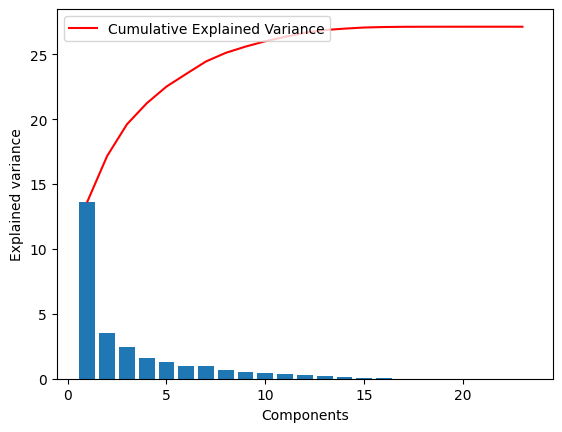

In [10]:
plt.bar(range(1, len(pca1.variances) + 1), pca1.variances)
plt.ylabel('Explained variance')
plt.xlabel('Components')
plt.plot(range(1, len(pca1.variances) + 1),
         np.cumsum(pca1.variances),
         c='red',
         label="Cumulative Explained Variance")
plt.legend(loc='upper left')

In [52]:
pca2 = PCA(0.95)
x_pca2 = pca2.fit_transform(x_train)
x_pca2.shape

(24, 10)

In [53]:
pca2c = PCA(n_components=2)
x_pca2c = pca2c.fit_transform(x_train)

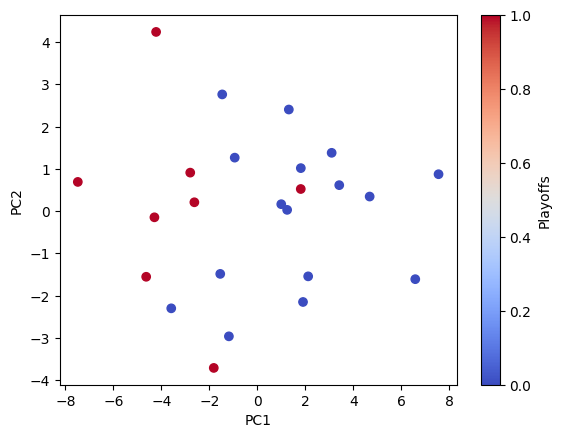

In [54]:
plt.figure()
scatter = plt.scatter(x_pca2c[:, 0], x_pca2c[:, 1], c=y_train, cmap='coolwarm')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.colorbar(scatter, label='Playoffs')
plt.show()

In [55]:
pca3c = PCA(n_components=3)
x_pca3c = pca3c.fit_transform(x_train)

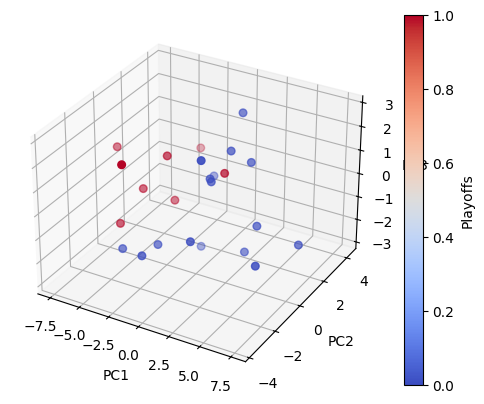

In [56]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
scatter = ax.scatter(x_pca3c[:, 0], x_pca3c[:, 1], x_pca3c[:, 2], c=y_train, cmap='coolwarm', s=30)
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
plt.colorbar(scatter, label='Playoffs')
plt.show()